In [ ]:
# Kütüphaneler
import os
import zipfile
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout, GlobalAveragePooling2D, Input, Conv2D, MaxPooling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
from google.colab import drive
import gc

# Drive'ı bağlama
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

# Zip Çıkarma
import os
import zipfile

# Ana Zipi Çıkarma
ana_zip_yolu = '/content/drive/MyDrive/YapayZekaProjesi/Brain Tumor MRI Dataset.zip'
gecici_klasor = '/content/temp_step1'

print(f"1. Ana zip dosyası ({ana_zip_yolu}) çıkarılıyor")
with zipfile.ZipFile(ana_zip_yolu, 'r') as zip_ref:
    zip_ref.extractall(gecici_klasor)

# İç Zipi Çıkarma
ic_zip_yolu = os.path.join(gecici_klasor, 'Brain Tumor MRI Dataset', 'Dataset.zip')
final_hedef = '/content/final_data'

print(f"2. İç zip dosyası ({ic_zip_yolu}) çıkarılıyor")
with zipfile.ZipFile(ic_zip_yolu, 'r') as zip_ref:
    zip_ref.extractall(final_hedef)

# Klasör Yollarını Tanımlama
train_dir = os.path.join(final_hedef, 'Dataset', 'Training')
test_dir = os.path.join(final_hedef, 'Dataset', 'Testing')

print(f"\n İşlem tamamlandı")
print(f"Eğitim Klasörü: {train_dir}")
print(f"Test Klasörü:   {test_dir}")

1. Ana zip dosyası (/content/drive/MyDrive/YapayZekaProjesi/Brain Tumor MRI Dataset.zip) çıkarılıyor
2. İç zip dosyası (/content/temp_step1/Brain Tumor MRI Dataset/Dataset.zip) çıkarılıyor

 İşlem tamamlandı
Eğitim Klasörü: /content/final_data/Dataset/Training
Test Klasörü:   /content/final_data/Dataset/Testing


/tmp/ipython-input-2422521782.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(train_sayi.keys()), y=list(train_sayi.values()), palette="viridis")
/tmp/ipython-input-2422521782.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(test_sayi.keys()), y=list(test_sayi.values()), palette="magma")


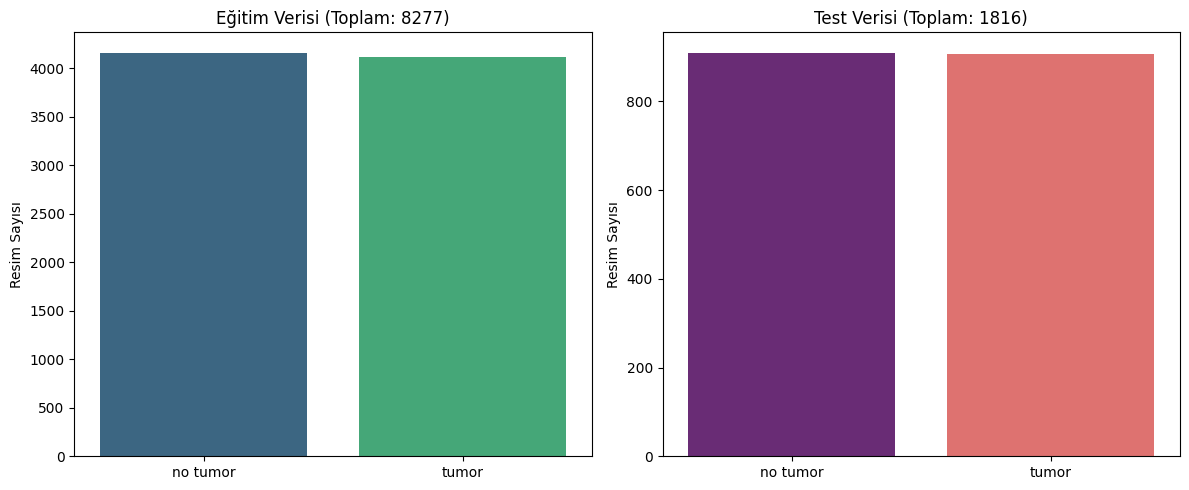

In [ ]:
# Keşifsel Veri Analizi(EDA)
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Sonuçların kaydedileceği klasörü oluşturma
kayit_yolu = '/content/drive/MyDrive/Proje_Sonuclari'
os.makedirs(kayit_yolu, exist_ok=True)

# Sayım Fonksiyonu
def say(yol):
    return {k: len(os.listdir(os.path.join(yol, k))) for k in os.listdir(yol)}

train_sayi = say(train_dir)
test_sayi = say(test_dir)

# Grafik Çizimi
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.barplot(x=list(train_sayi.keys()), y=list(train_sayi.values()), palette="viridis")
plt.title(f"Eğitim Verisi (Toplam: {sum(train_sayi.values())})")
plt.ylabel("Resim Sayısı")

plt.subplot(1, 2, 2)
sns.barplot(x=list(test_sayi.keys()), y=list(test_sayi.values()), palette="magma")
plt.title(f"Test Verisi (Toplam: {sum(test_sayi.values())})")
plt.ylabel("Resim Sayısı")

plt.tight_layout()

# Kayıt ve çıktı
dosya_adi = os.path.join(kayit_yolu, 'Veri_Dagilimi_EDA.png')
plt.savefig(dosya_adi)

plt.show()

In [ ]:
# Veri hazırlığı ve augmentation
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Resim Boyutları
IMG_SIZE = (224, 224)
BATCH_SIZE = 32


# Training datası için model ezberlemesin diye çoğaltma yapma
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
    fill_mode='nearest'
)

# Test datası için augmentation yok
test_datagen = ImageDataGenerator(
    rescale=1./255
)

# Verileri Klasörlerden Okuma
print(f"Eğitim verisi okunuyor: {train_dir}")
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

print(f"Test verisi okunuyor: {test_dir}")
test_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

# Sınıfları Görme
class_names = list(train_generator.class_indices.keys())
print(f"\n Tespit Edilen Sınıflar: {class_names}")

Eğitim verisi okunuyor: /content/final_data/Dataset/Training
Found 8277 images belonging to 2 classes.
Test verisi okunuyor: /content/final_data/Dataset/Testing
Found 1816 images belonging to 2 classes.

 Tespit Edilen Sınıflar: ['no tumor', 'tumor']


In [ ]:
# Raporlama ve gösterim
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import os

# Sonuçların kaydedileceği ana klasör
RESULTS_DIR = '/content/drive/MyDrive/Proje_Sonuclari'
os.makedirs(RESULTS_DIR, exist_ok=True)

def raporla_ve_kaydet(model, history, test_gen, model_name, sure):
    print(f"\n{model_name} için sonuçlar hazırlanıyor")
    save_path = os.path.join(RESULTS_DIR, model_name)
    os.makedirs(save_path, exist_ok=True)

    # EN YÜKSEK BAŞARIYI BULMA
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(1, len(acc) + 1)

    en_iyi_skor = max(val_acc) # En yüksek test başarısı
    en_iyi_epoch = val_acc.index(en_iyi_skor) + 1

    print(f"{model_name} En İyi Test Başarısı: %{en_iyi_skor*100:.2f} (Epoch {en_iyi_epoch})")

    # ACCURACY & LOSS GRAFİKLERİ
    plt.figure(figsize=(14, 6))

    # Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation (Test) Accuracy')
    plt.scatter(en_iyi_epoch, en_iyi_skor, c='red', label=f'En İyi: {en_iyi_skor:.2f}')
    plt.title(f'{model_name} - Accuracy (En İyi: {en_iyi_skor:.2f})')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend(loc='lower right')
    plt.grid(True)

    # Loss
    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation (Test) Loss')
    plt.title(f'{model_name} - Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend(loc='upper right')
    plt.grid(True)

    plt.savefig(f"{save_path}/{model_name}_Accuracy_Loss.png")
    plt.show() # ekranda gösterme

    # CONFUSION MATRIX
    test_gen.reset()
    predictions = model.predict(test_gen, verbose=0)
    y_pred = np.argmax(predictions, axis=1)
    y_true = test_gen.classes

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=list(test_gen.class_indices.keys()),
                yticklabels=list(test_gen.class_indices.keys()))
    plt.title(f'{model_name} Confusion Matrix')
    plt.ylabel('Gerçek')
    plt.xlabel('Tahmin')
    plt.savefig(f"{save_path}/{model_name}_Confusion_Matrix.png")
    plt.show() # ekranda gösterme

    # ROC EĞRİLERİ
    plt.figure(figsize=(10, 8))
    y_true_dummies = pd.get_dummies(y_true).values
    n_classes = len(list(test_gen.class_indices.keys()))

    for i in range(n_classes):
        fpr, tpr, _ = roc_curve(y_true_dummies[:, i], predictions[:, i])
        roc_val = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f'Sınıf {i} (AUC = {roc_val:.2f})')

    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'{model_name} ROC Eğrileri')
    plt.legend(loc="lower right")
    plt.savefig(f"{save_path}/{model_name}_ROC.png")
    plt.show() # Ekranda çıktı

    # RAPOR DOSYASI
    report = classification_report(y_true, y_pred, target_names=list(test_gen.class_indices.keys()))
    with open(f"{save_path}/{model_name}_Metrics.txt", "w") as f:
        f.write(report)
        f.write(f"\n\nEğitim Süresi: {sure:.2f} saniye")
        f.write(f"\nEn Yüksek Başarı: {en_iyi_skor:.4f}")

    return en_iyi_skor, sure

In [ ]:
# Model mimarileri
from tensorflow.keras.applications import VGG16, ResNet50, InceptionV3, DenseNet121, MobileNetV2, Xception, InceptionResNetV2, NASNetMobile,VGG19
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization, Conv2D, MaxPooling2D, Flatten, Input, Concatenate
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

def get_model(model_name, input_shape, num_classes):

    # Kendi modelim
    if model_name == "My_Custom_CNN":
        model = Sequential([
            Input(shape=input_shape),

            Conv2D(32, (3, 3), activation='relu', padding='same'),
            BatchNormalization(), # Öğrenmeyi dengelemek için
            MaxPooling2D(2, 2),

            Conv2D(64, (3, 3), activation='relu', padding='same'),
            BatchNormalization(),
            MaxPooling2D(2, 2),
            Dropout(0.25), # Ezberlemeyi önleme

            Conv2D(128, (3, 3), activation='relu', padding='same'),
            BatchNormalization(),
            MaxPooling2D(2, 2),
            Dropout(0.3),

            Conv2D(256, (3, 3), activation='relu', padding='same'),
            BatchNormalization(),
            MaxPooling2D(2, 2),
            Dropout(0.4),

            # Sınıflandırma Kısmı
            Flatten(),
            Dense(512, activation='relu', kernel_regularizer=l2(0.001)), # L2: Hata farkını baskılar
            Dropout(0.5),
            Dense(num_classes, activation='softmax')
        ])

        optimizer = Adam(learning_rate=0.0001)
        model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])
        return model

    # Hazır modeller
    base_model = None

    if model_name == "VGG16":
        base_model = VGG16(weights='imagenet', include_top=False, input_shape=input_shape)
    elif model_name == "ResNet50":
        base_model = ResNet50(weights='imagenet', include_top=False, input_shape=input_shape)
    elif model_name == "InceptionV3":
        base_model = InceptionV3(weights='imagenet', include_top=False, input_shape=input_shape)
    elif model_name == "DenseNet121":
        base_model = DenseNet121(weights='imagenet', include_top=False, input_shape=input_shape)
    elif model_name == "MobileNetV2":
        base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=input_shape)
    elif model_name == "Xception":
        base_model = Xception(weights='imagenet', include_top=False, input_shape=input_shape)
    elif model_name == "InceptionResNetV2":
        base_model = InceptionResNetV2(weights='imagenet', include_top=False, input_shape=input_shape)
    elif model_name == "NASNetMobile":
        base_model = NASNetMobile(weights='imagenet', include_top=False, input_shape=input_shape)
    elif model_name == "VGG19":
        base_model = VGG19(weights='imagenet', include_top=False, input_shape=input_shape)


    if base_model:
        for layer in base_model.layers:
            layer.trainable = False

        x = base_model.output
        x = GlobalAveragePooling2D()(x)
        x = Dense(256, activation='relu')(x)
        x = Dropout(0.4)(x) # Overfitting önlemi
        predictions = Dense(num_classes, activation='softmax')(x)

        model = Model(inputs=base_model.input, outputs=predictions)
        model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])
        return model

    # Hiibrit model (DenseNet121 + InceptionV3)
    elif model_name == "Hybrid_Model":
        input_layer = Input(shape=input_shape)

        # Model A: DenseNet121
        model_a = DenseNet121(weights='imagenet', include_top=False, input_tensor=input_layer)
        for layer in model_a.layers: layer.trainable = False
        out_a = GlobalAveragePooling2D()(model_a.output)

        # Model B: InceptionV3
        model_b = InceptionV3(weights='imagenet', include_top=False, input_tensor=input_layer)
        for layer in model_b.layers: layer.trainable = False
        out_b = GlobalAveragePooling2D()(model_b.output)

        # Birleştirme
        combined = Concatenate()([out_a, out_b])

        # Son Karar Katmanı
        z = Dense(256, activation='relu')(combined)
        z = Dropout(0.5)(z)
        output = Dense(num_classes, activation='softmax')(z)

        model = Model(inputs=input_layer, outputs=output)
        model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])
        return model

    else:
        print(f"HATA: '{model_name}' isminde bir model tanımlı değil!")
        return None

print(" Model mimarileri tamamlandı")

 Model mimarileri tamamlandı


In [ ]:
# Eğitim ve Kayıt
import time
import os
import gc
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras import backend as K

# Sonuçların kaydedileceği yer
RESULTS_DIR = '/content/drive/MyDrive/Proje_Sonuclari'
os.makedirs(RESULTS_DIR, exist_ok=True)

def modeli_calistir(model_ismi):
    print(f"\n" + "="*60)
    print(f"SİSTEM: '{model_ismi}' Modeli çalıştırılıyor")
    print("="*60)

    # 1. Model Yapılandırması
    try:
        num_classes = len(class_names)
        print(f"Sınıf sayısı tespit edildi: {num_classes}")
    except NameError:
        print("'class_names' değişkeni bulunamadı")
        return

    model = get_model(model_ismi, input_shape=(224, 224, 3), num_classes=num_classes)

    if model is None:
        print(f"Model oluşturulamadı: {model_ismi}")
        return
    else:
        print(f"Model başarıyla yüklendi: {model_ismi}")

    model_save_path = os.path.join(RESULTS_DIR, model_ismi)
    os.makedirs(model_save_path, exist_ok=True)

    # En iyi için dosya yolu
    checkpoint_file = os.path.join(model_save_path, f"{model_ismi}_best_model.keras")

    checkpoint = ModelCheckpoint(
        checkpoint_file,
        monitor='val_accuracy',
        verbose=1,
        save_best_only=True,
        mode='max'
    )

    # Öğrenme oranını iyileştirme
    reduce_lr = ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=4,
        min_lr=0.00001,
        verbose=1
    )

    # Model eğitimi
    start_time = time.time()

    try:
        history = model.fit(
            train_generator,
            epochs=50,
            validation_data=test_generator,
            callbacks=[checkpoint, reduce_lr],
            verbose=1
        )
    except Exception as e:
        print(f"Eğitim sırasında hata oldu: {e}")
        return

    end_time = time.time()
    sure_saniye = end_time - start_time
    print(f"Eğitim tamamlandı. Toplam Süre: {sure_saniye:.2f} saniye")

    # Raporlama ve görselleştirme kısmı
    try:
        son_dogruluk, sure = raporla_ve_kaydet(model, history, test_generator, model_ismi, sure_saniye)
        print(f"{model_ismi} modeli test doğruluğu: {son_dogruluk:.4f}")
    except Exception as e:
        print(f"Raporamada hata oluştu: {e}")

    # Ram temizleme
    print(f"RAM temizleniyor")
    del model
    del history
    gc.collect()
    K.clear_session()
    print(f"'{model_ismi}'modeli tamamlandı.\n")

In [ ]:
# Eğitim ve Kayıt
import time, os, gc
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras import backend as K

RESULTS_DIR = '/content/drive/MyDrive/Proje_Sonuclari'

def modeli_calistir(model_ismi):
    print(f"\n {model_ismi} modeli için işlem başlatılıyor")

    # Model Kurulumu
    num_classes = len(class_names)
    model = get_model(model_ismi, input_shape=(224, 224, 3), num_classes=num_classes)
    if model is None: return

    # Kayıt ve Ayarlar
    save_path = os.path.join(RESULTS_DIR, model_ismi)
    os.makedirs(save_path, exist_ok=True)

    checkpoint = ModelCheckpoint(os.path.join(save_path, f"{model_ismi}_best.keras"),
                                 monitor='val_accuracy', save_best_only=True, mode='max', verbose=1)
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=4, min_lr=0.00001, verbose=1)

    # 50 Epoch Eğitim
    start = time.time()
    history = model.fit(train_generator, epochs=50, validation_data=test_generator,
                        callbacks=[checkpoint, reduce_lr], verbose=1)

    # Raporlama
    best_acc, _ = raporla_ve_kaydet(model, history, test_generator, model_ismi, time.time() - start)
    print(f"{model_ismi} Tamamlandı. En Yüksek Başarı: %{best_acc*100:.2f}")

    # Hafıza Temizliği
    del model, history
    gc.collect()
    K.clear_session()

In [ ]:
# Kendi modelim
# Fonksiyonu çağırma
modeli_calistir("My_Custom_CNN")


SİSTEM: 'My_Custom_CNN' Modeli çalıştırılıyor
Sınıf sayısı tespit edildi: 2
Model başarıyla yüklendi: My_Custom_CNN


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 469ms/step - accuracy: 0.8131 - loss: 2.1018
Epoch 1: val_accuracy improved from -inf to 0.49890, saving model to /content/drive/MyDrive/Proje_Sonuclari/My_Custom_CNN/My_Custom_CNN_best_model.keras
259/259 ━━━━━━━━━━━━━━━━━━━━ 151s 520ms/step - accuracy: 0.8133 - loss: 2.0994 - val_accuracy: 0.4989 - val_loss: 6.0956 - learning_rate: 1.0000e-04
Epoch 2/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 434ms/step - accuracy: 0.9308 - loss: 1.0830
Epoch 2: val_accuracy improved from 0.49890 to 0.82159, saving model to /content/drive/MyDrive/Proje_Sonuclari/My_Custom_CNN/My_Custom_CNN_best_model.keras
259/259 ━━━━━━━━━━━━━━━━━━━━ 118s 456ms/step - accuracy: 0.9309 - loss: 1.0829 - val_accuracy: 0.8216 - val_loss: 1.5501 - learning_rate: 1.0000e-04
Epoch 3/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 460ms/step - accuracy: 0.9474 - loss: 0.9715
Epoch 3: val_accuracy improved from 0.82159 to 0.89262, saving model to /content/drive/MyDrive/Proje_Sonuclari/My_Custom_CNN/My_C


 VGG16 modeli için işlem başlatılıyor
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 474ms/step - accuracy: 0.6226 - loss: 0.6529
Epoch 1: val_accuracy improved from -inf to 0.87885, saving model to /content/drive/MyDrive/Proje_Sonuclari/VGG16/VGG16_best.keras
259/259 ━━━━━━━━━━━━━━━━━━━━ 159s 559ms/step - accuracy: 0.6229 - loss: 0.6526 - val_accuracy: 0.8789 - val_loss: 0.4295 - learning_rate: 1.0000e-04
Epoch 2/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 435ms/step - accuracy: 0.8560 - loss: 0.4069
Epoch 2: val_accuracy improved from 0.87885 to 0.91465, saving model to /content/drive/MyDrive/Proje_Sonuclari/VGG16/VGG16_best.keras
259/259 ━━━━━━━━━━━━━━━━━━━━ 123s 474ms/step - accuracy: 0.8561 - loss: 0.4068 - val_accuracy: 0.9146 - val_loss: 0.3208 - learning_rate: 1.0000e-04
Epoch 3/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 428ms/step - accuracy: 0.9066 - loss: 0.2933
Epoch 3: val_accuracy improved from 0.91465 to 0.92511, saving model to /content/drive/MyDrive/Proje_Sonuclari/VGG16/VGG16_best.keras
259/259 ━━━━━━━━━━━━━━━━━━━━ 121s 467ms

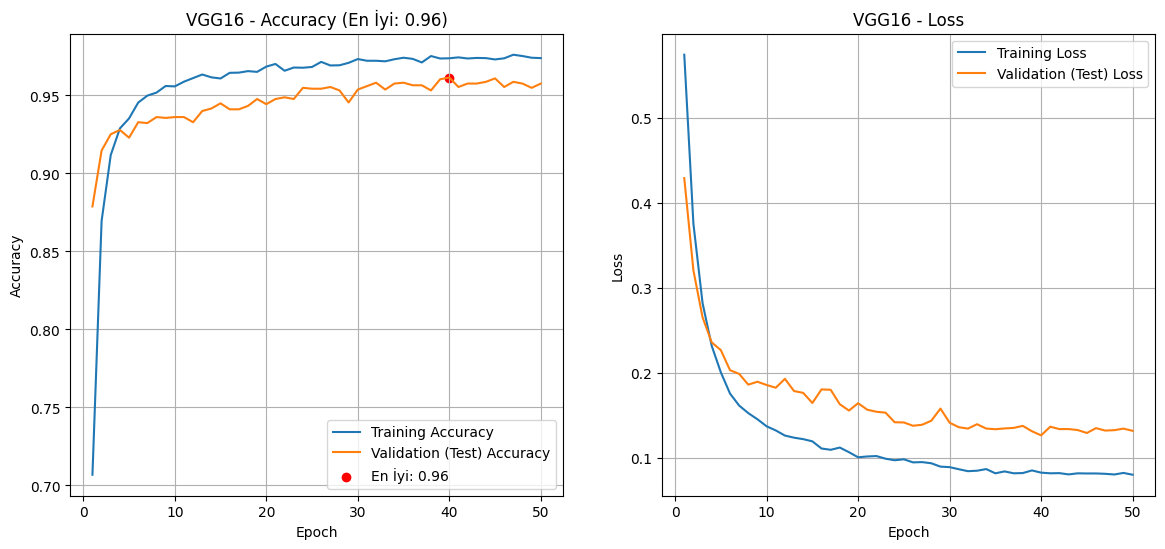

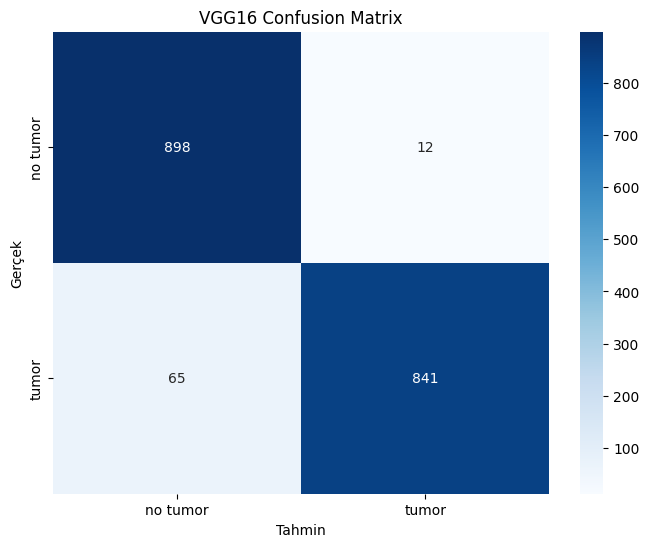

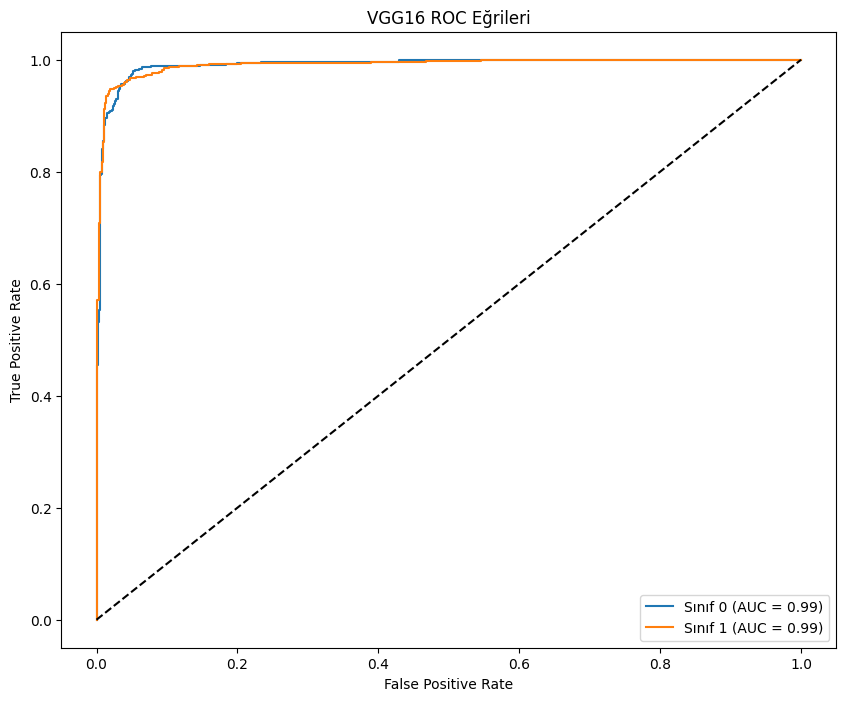

VGG16 Tamamlandı. En Yüksek Başarı: %96.15


In [ ]:
# Hazır model eğitimi


# 1. VGG16
modeli_calistir("VGG16")


 ResNet50 modeli için işlem başlatılıyor
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 420ms/step - accuracy: 0.5602 - loss: 0.7384
Epoch 1: val_accuracy improved from -inf to 0.74725, saving model to /content/drive/MyDrive/Proje_Sonuclari/ResNet50/ResNet50_best.keras
259/259 ━━━━━━━━━━━━━━━━━━━━ 136s 473ms/step - accuracy: 0.5604 - loss: 0.7381 - val_accuracy: 0.7472 - val_loss: 0.5513 - learning_rate: 1.0000e-04
Epoch 2/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 404ms/step - accuracy: 0.7328 - loss: 0.5423
Epoch 2: val_accuracy improved from 0.74725 to 0.81167, saving model to /content/drive/MyDrive/Proje_Sonuclari/ResNet50/ResNet50_best.keras
259/259 ━━━━━━━━━━━━━━━━━━━━ 110s 426ms/step - accuracy: 0.7329 - loss: 0.5423 - val_accuracy: 0.8117 - val_loss: 0.4960 - learning_rate: 1.0000e-04
Epoch 3/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step - accuracy: 0.8069 - loss: 0.4649
Epoch 3: val_accuracy improved from 0.81167 to 0.87885, saving model

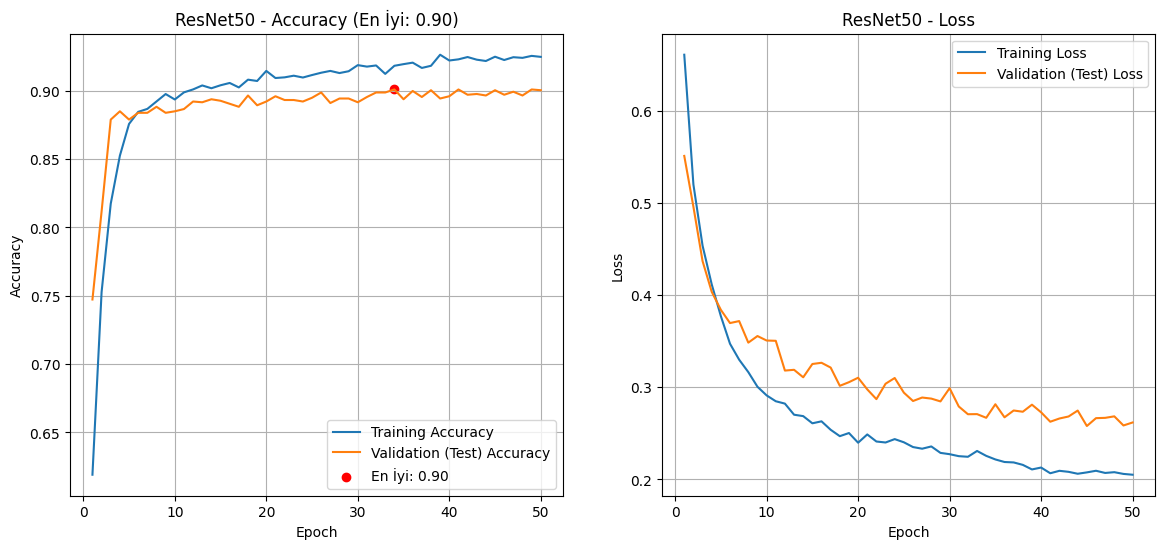

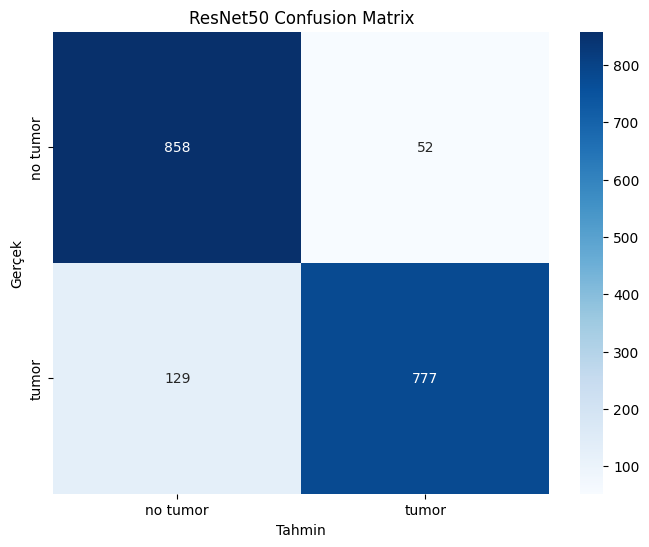

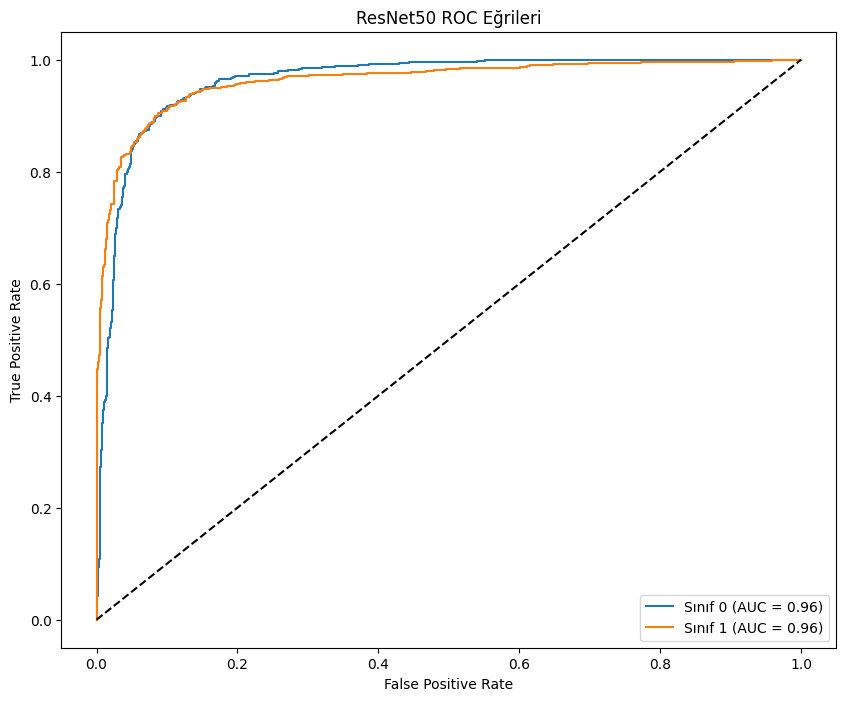

ResNet50 Tamamlandı. En Yüksek Başarı: %90.09


In [ ]:
# Hazır model eğitimi
# 2.RESNET50

modeli_calistir("ResNet50")


 InceptionV3 modeli için işlem başlatılıyor
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 446ms/step - accuracy: 0.8006 - loss: 0.4274
Epoch 1: val_accuracy improved from -inf to 0.93282, saving model to /content/drive/MyDrive/Proje_Sonuclari/InceptionV3/InceptionV3_best.keras
259/259 ━━━━━━━━━━━━━━━━━━━━ 152s 520ms/step - accuracy: 0.8009 - loss: 0.4269 - val_accuracy: 0.9328 - val_loss: 0.1842 - learning_rate: 1.0000e-04
Epoch 2/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 407ms/step - accuracy: 0.9412 - loss: 0.1598
Epoch 2: val_accuracy improved from 0.93282 to 0.94769, saving model to /content/drive/MyDrive/Proje_Sonuclari/InceptionV3/InceptionV3_best.keras
259/259 ━━━━━━━━━━━━━━━━━━━━ 110s 425ms/step - accuracy: 0.9412 - loss: 0.1598 - val_accuracy: 0.9477 - val_loss: 0.1541 - learning_rate: 1.0000e-04
Epoch 3/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 404ms/step - accuracy: 0.9494 - loss: 0.1435
Epoch 3: val_accuracy improved from 0.94769 to 0.95485, saving model to /content/drive/MyDrive/Proje_Sonuclari/InceptionV3/InceptionV3_best.keras
259

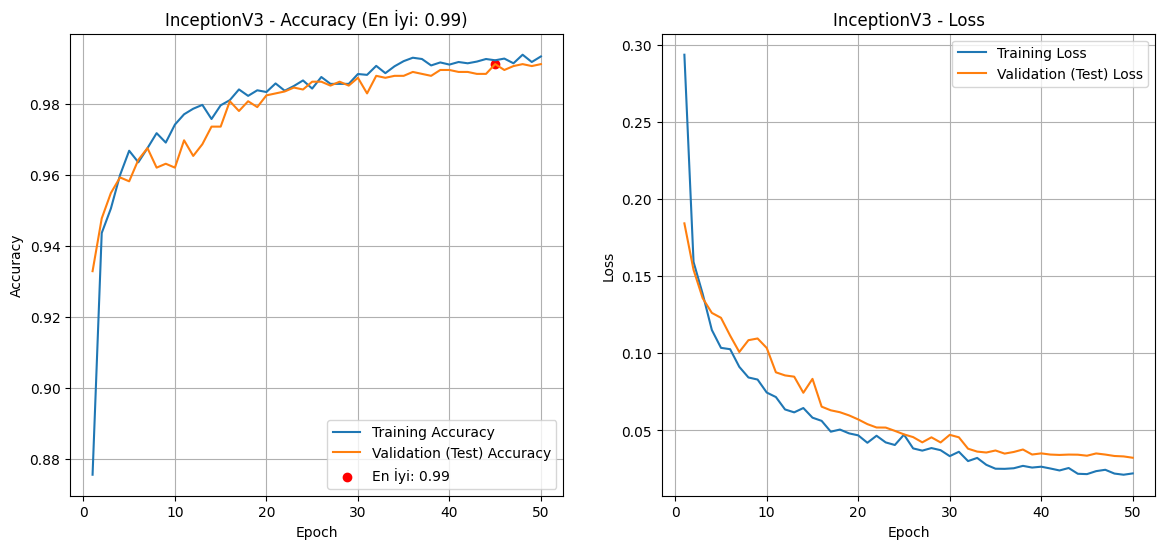

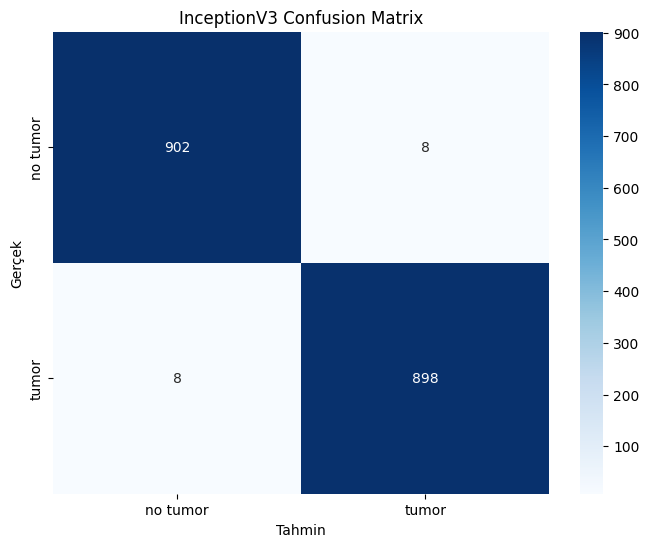

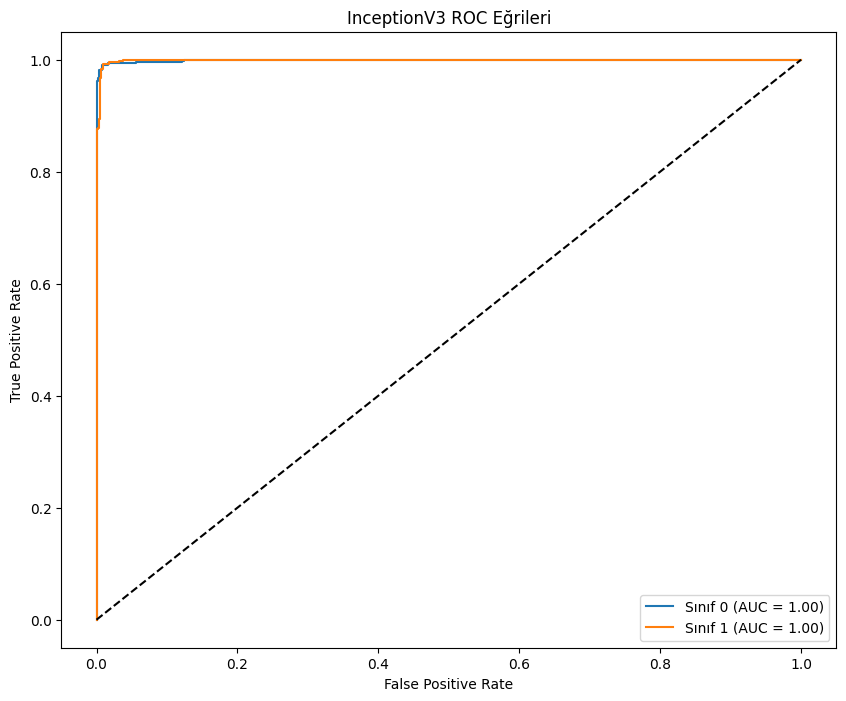

InceptionV3 Tamamlandı. En Yüksek Başarı: %99.12


In [ ]:
# Hazır model eğitimi
# 3.InceptionV3

modeli_calistir("InceptionV3")


 DenseNet121 modeli için işlem başlatılıyor
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 454ms/step - accuracy: 0.7592 - loss: 0.5023
Epoch 1: val_accuracy improved from -inf to 0.94548, saving model to /content/drive/MyDrive/Proje_Sonuclari/DenseNet121/DenseNet121_best.keras
259/259 ━━━━━━━━━━━━━━━━━━━━ 179s 575ms/step - accuracy: 0.7596 - loss: 0.5016 - val_accuracy: 0.9455 - val_loss: 0.1778 - learning_rate: 1.0000e-04
Epoch 2/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 406ms/step - accuracy: 0.9459 - loss: 0.1595
Epoch 2: val_accuracy improved from 0.94548 to 0.95595, saving model to /content/drive/MyDrive/Proje_Sonuclari/DenseNet121/DenseNet121_best.keras
259/259 ━━━━━━━━━━━━━━━━━━━━ 111s 428ms/step - accuracy: 0.9459 - loss: 0.1595 - val_accuracy: 0.9559 - val_loss: 0.1446 - learning_rate: 1.0000e-04
Epoch 3/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 412ms/step - accuracy: 0.9595 - loss: 0.1193
Epoch 3: val_accuracy improved from 0.95595 to 0.9587

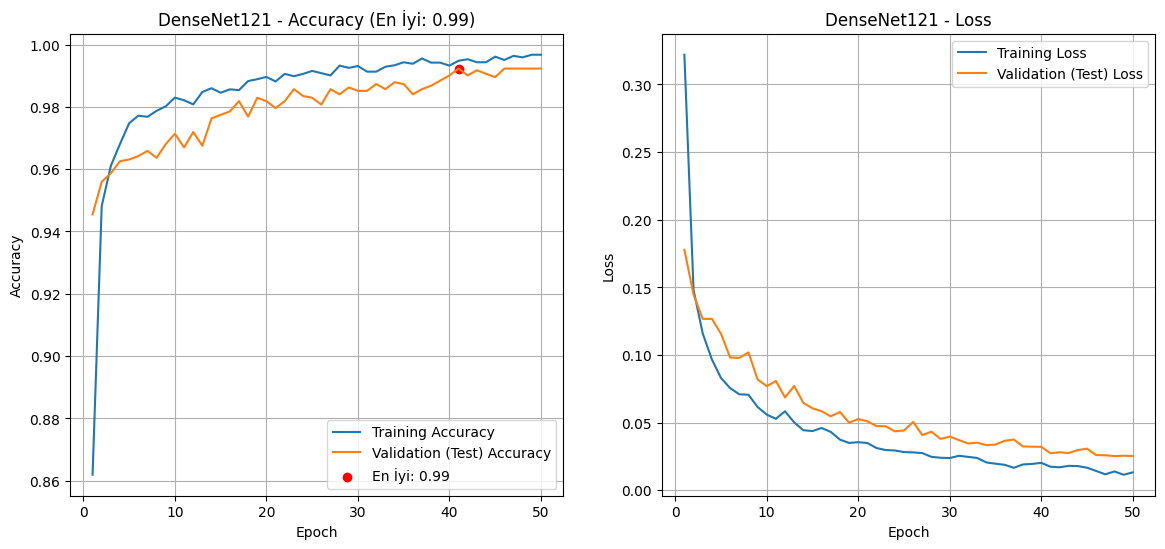

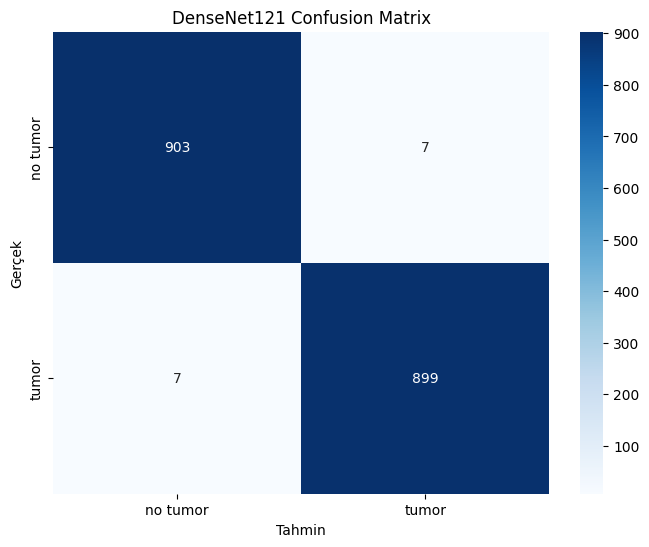

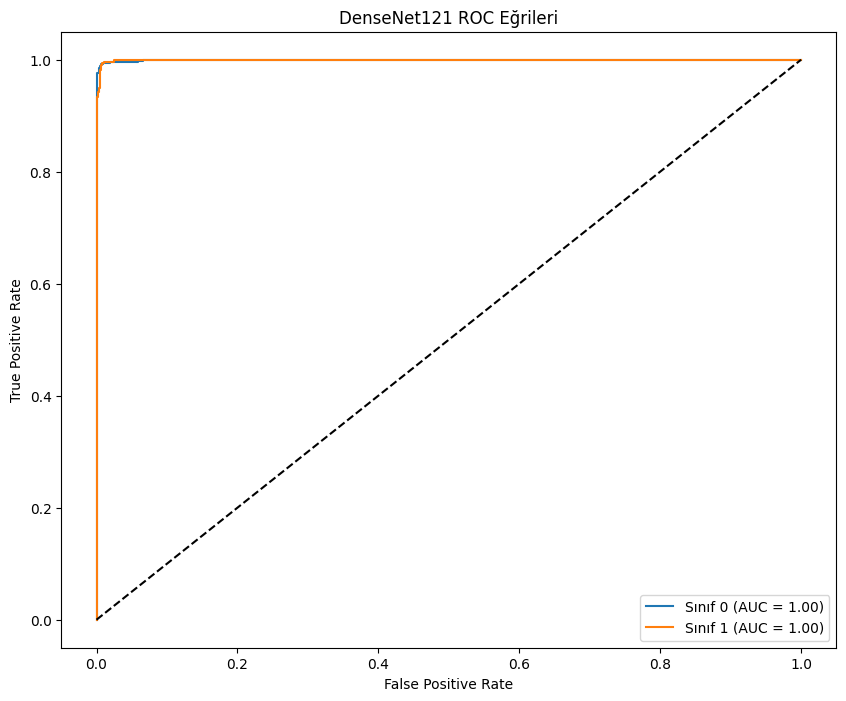

DenseNet121 Tamamlandı. En Yüksek Başarı: %99.23


In [ ]:
# Hazır model eğitimi
# 4.DenseNet121

modeli_calistir("DenseNet121")


 MobileNetV2 modeli için işlem başlatılıyor
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 445ms/step - accuracy: 0.8292 - loss: 0.3600
Epoch 1: val_accuracy improved from -inf to 0.93337, saving model to /content/drive/MyDrive/Proje_Sonuclari/MobileNetV2/MobileNetV2_best.keras
259/259 ━━━━━━━━━━━━━━━━━━━━ 154s 519ms/step - accuracy: 0.8295 - loss: 0.3595 - val_accuracy: 0.9334 - val_loss: 0.1868 - learning_rate: 1.0000e-04
Epoch 2/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 378ms/step - accuracy: 0.9611 - loss: 0.1291
Epoch 2: val_accuracy improved from 0.93337 to 0.94659, saving model to /content/drive/MyDrive/Proje_Sonuclari/MobileNetV2/MobileNetV2_best.keras
259/259 ━━━━━━━━━━━━━━━━━━━━ 102s 393ms/step - accuracy: 0.9611 - loss: 0.1291 - val_accuracy: 0.9466 - val_loss: 0.1509 - learning_rate: 1.0000e-04
Epoch 3/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 381ms/step - accuracy: 0.9712 - loss: 0.0930
Epoch 3: val_accuracy improved from 0.94659 to 0.95540, saving model to /content/drive/MyDrive/Proje_Sonuclari/MobileNetV2/MobileNetV2_best.keras
259

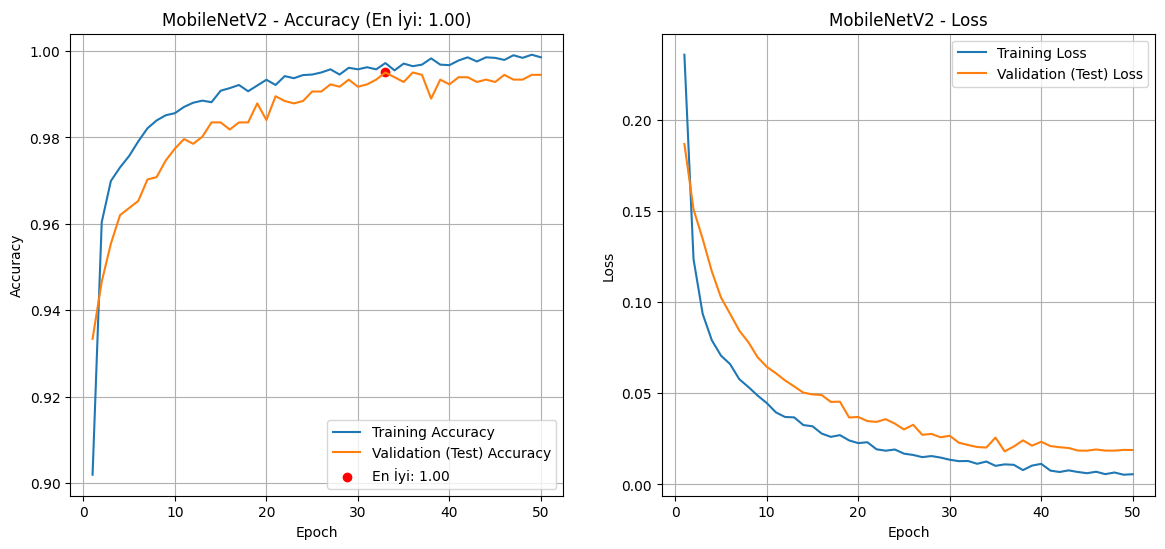

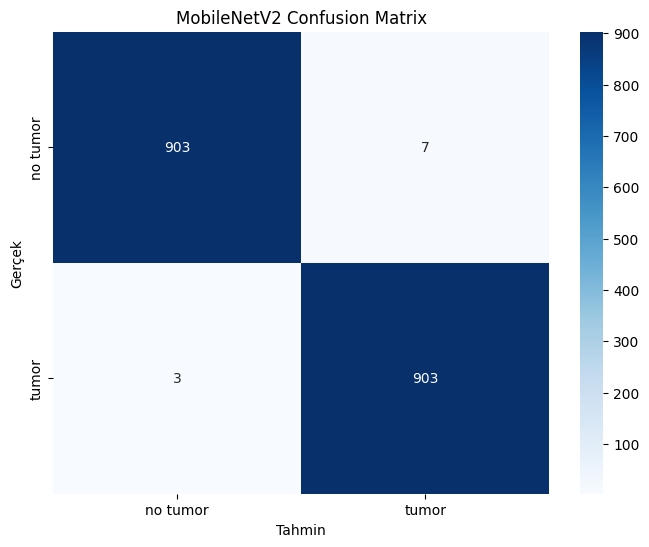

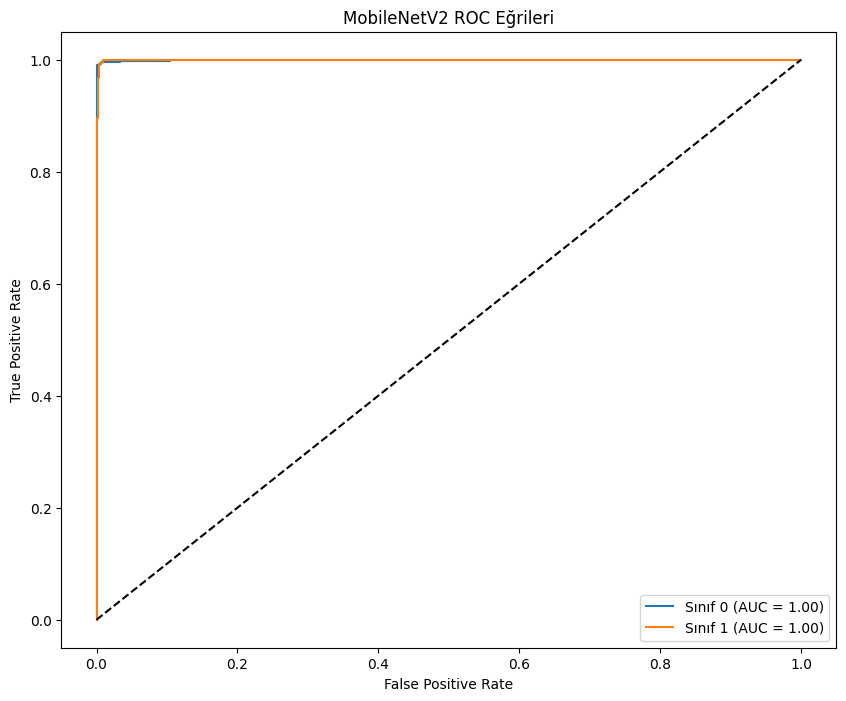

MobileNetV2 Tamamlandı. En Yüksek Başarı: %99.50


In [ ]:
# Hazır model eğitimi
# 5.MobileNetV2

modeli_calistir("MobileNetV2")


 Xception modeli için işlem başlatılıyor
83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 486ms/step - accuracy: 0.8294 - loss: 0.3690
Epoch 1: val_accuracy improved from -inf to 0.93943, saving model to /content/drive/MyDrive/Proje_Sonuclari/Xception/Xception_best.keras
259/259 ━━━━━━━━━━━━━━━━━━━━ 176s 587ms/step - accuracy: 0.8297 - loss: 0.3686 - val_accuracy: 0.9394 - val_loss: 0.1740 - learning_rate: 1.0000e-04
Epoch 2/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 419ms/step - accuracy: 0.9443 - loss: 0.1518
Epoch 2: val_accuracy improved from 0.93943 to 0.95540, saving model to /content/drive/MyDrive/Proje_Sonuclari/Xception/Xception_best.keras
259/259 ━━━━━━━━━━━━━━━━━━━━ 116s 449ms/step - accuracy: 0.9443 - loss: 0.1517 - val_accuracy: 0.9554 - val_loss: 0.1419 - learning_rate: 1.0000e-04
Epoch 3/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 427ms/step - accuracy: 0.9662 - loss: 0.1082
Epoch 3: val_accuracy did not improve from 0.95540
259/259 ━━━━━━━━━━━━━━━━━━━━ 118s 455ms/step - accuracy: 0.9662 - loss: 0.1082 - val_accuracy: 0.9548 - val_lo

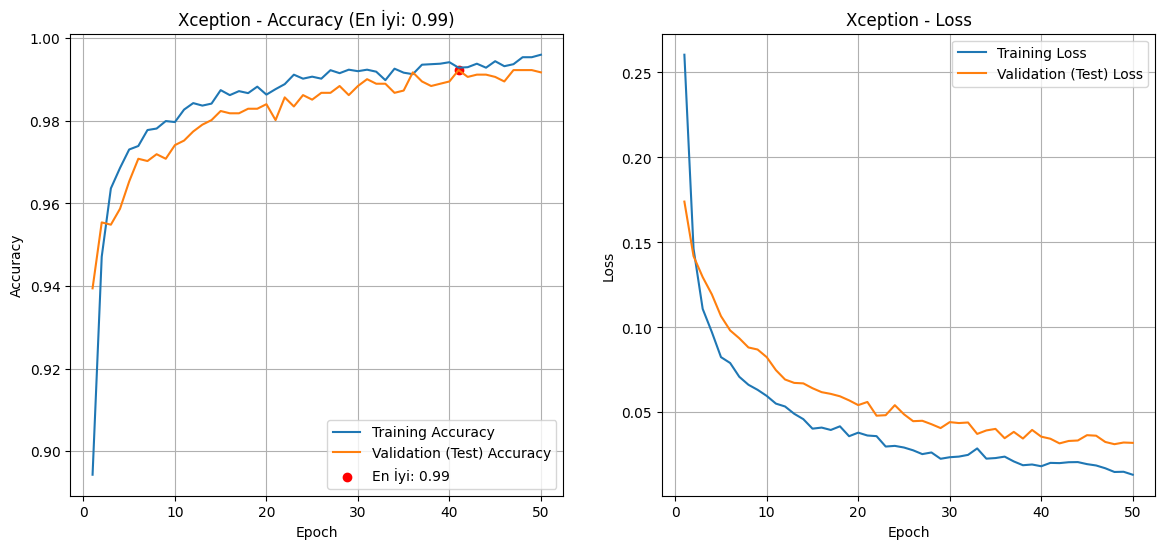

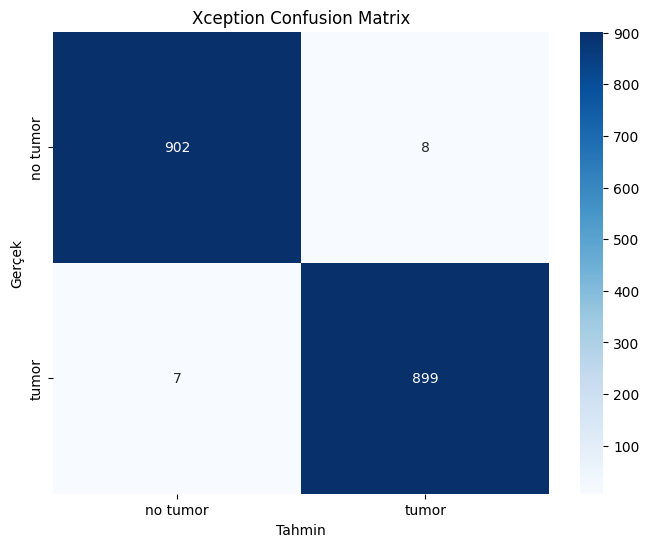

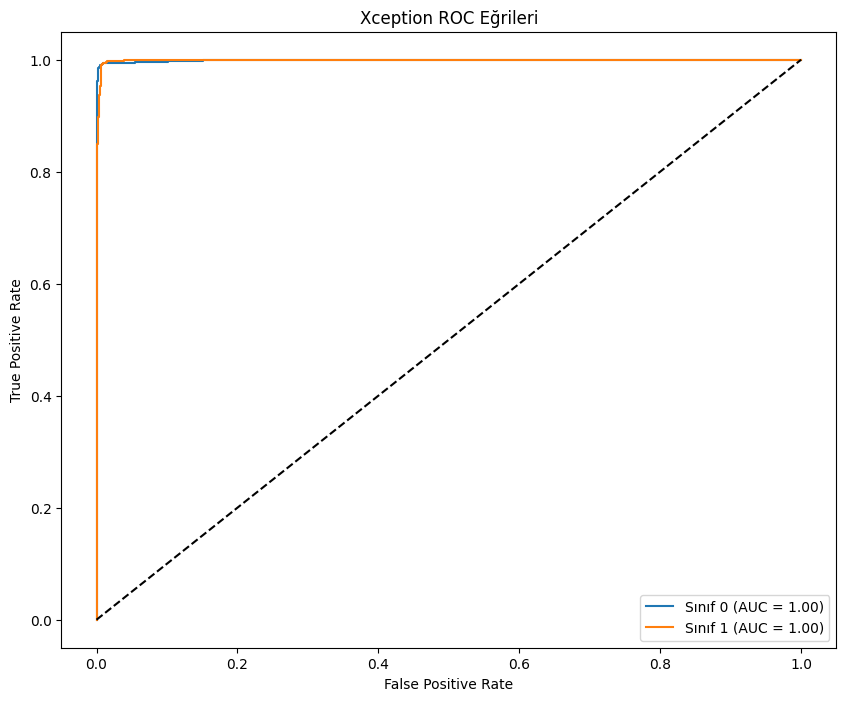

Xception Tamamlandı. En Yüksek Başarı: %99.23


In [ ]:
# Hazır model eğitimi
#6.Xception

modeli_calistir("Xception")


 NASNetMobile modeli için işlem başlatılıyor
19993432/19993432 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 492ms/step - accuracy: 0.7988 - loss: 0.4239
Epoch 1: val_accuracy improved from -inf to 0.91630, saving model to /content/drive/MyDrive/Proje_Sonuclari/NASNetMobile/NASNetMobile_best.keras
259/259 ━━━━━━━━━━━━━━━━━━━━ 219s 671ms/step - accuracy: 0.7991 - loss: 0.4234 - val_accuracy: 0.9163 - val_loss: 0.2182 - learning_rate: 1.0000e-04
Epoch 2/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 395ms/step - accuracy: 0.9218 - loss: 0.2044
Epoch 2: val_accuracy improved from 0.91630 to 0.92456, saving model to /content/drive/MyDrive/Proje_Sonuclari/NASNetMobile/NASNetMobile_best.keras
259/259 ━━━━━━━━━━━━━━━━━━━━ 109s 419ms/step - accuracy: 0.9218 - loss: 0.2044 - val_accuracy: 0.9246 - val_loss: 0.1883 - learning_rate: 1.0000e-04
Epoch 3/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 390ms/step - accuracy: 0.9373 - loss: 0.1630
Epoch 3: val_accuracy improved from 0.92456 to 0.93227, saving model to /content/drive/MyDrive/Proje_Sonuclari/NASNetMobile/NASNetMobile_best.ker

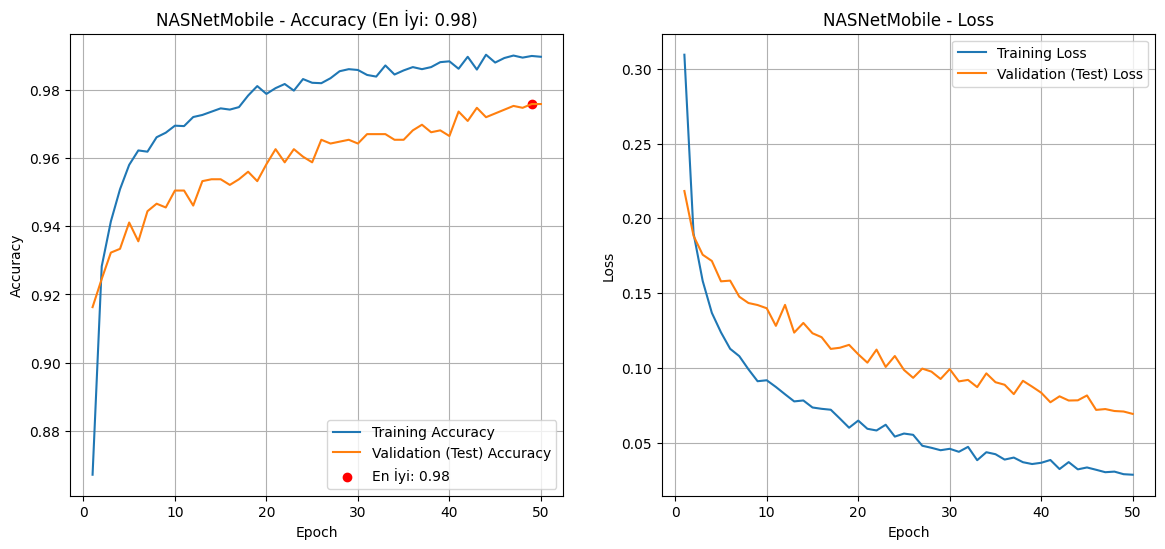

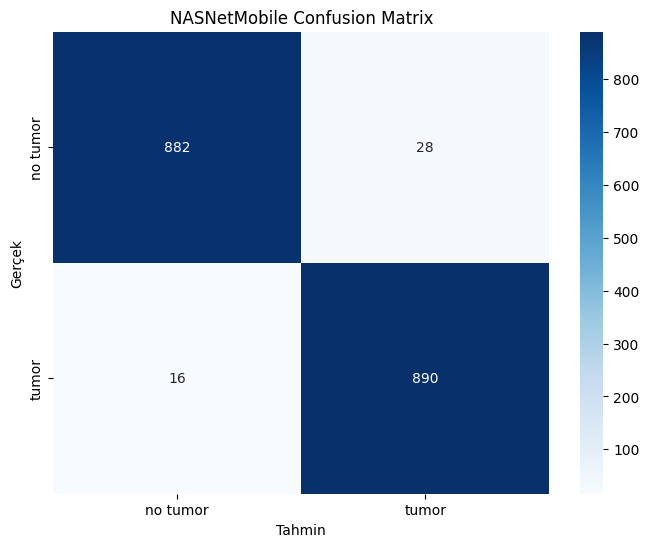

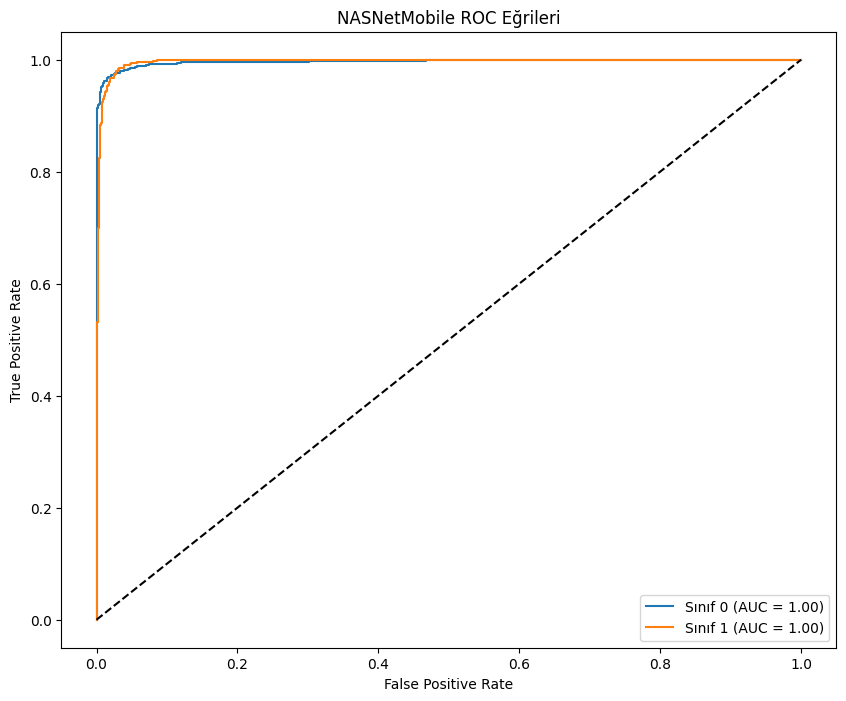

NASNetMobile Tamamlandı. En Yüksek Başarı: %97.58


In [ ]:
# Hazır model eğitimi
# 7.NASNetMobile

modeli_calistir("NASNetMobile")


 VGG19 modeli için işlem başlatılıyor
Epoch 1/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 479ms/step - accuracy: 0.5883 - loss: 0.6772

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()



Epoch 1: val_accuracy improved from -inf to 0.84251, saving model to /content/drive/MyDrive/Proje_Sonuclari/VGG19/VGG19_best.keras
259/259 ━━━━━━━━━━━━━━━━━━━━ 161s 563ms/step - accuracy: 0.5886 - loss: 0.6769 - val_accuracy: 0.8425 - val_loss: 0.4471 - learning_rate: 1.0000e-04
Epoch 2/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 448ms/step - accuracy: 0.8292 - loss: 0.4397
Epoch 2: val_accuracy improved from 0.84251 to 0.88271, saving model to /content/drive/MyDrive/Proje_Sonuclari/VGG19/VGG19_best.keras
259/259 ━━━━━━━━━━━━━━━━━━━━ 137s 529ms/step - accuracy: 0.8293 - loss: 0.4396 - val_accuracy: 0.8827 - val_loss: 0.3436 - learning_rate: 1.0000e-04
Epoch 3/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 440ms/step - accuracy: 0.8719 - loss: 0.3392
Epoch 3: val_accuracy improved from 0.88271 to 0.90804, saving model to /content/drive/MyDrive/Proje_Sonuclari/VGG19/VGG19_best.keras
259/259 ━━━━━━━━━━━━━━━━━━━━ 131s 485ms/step - accuracy: 0.8719 - loss: 0.3391 - val_accuracy: 0.9080 - val_loss: 0.2805 - lea

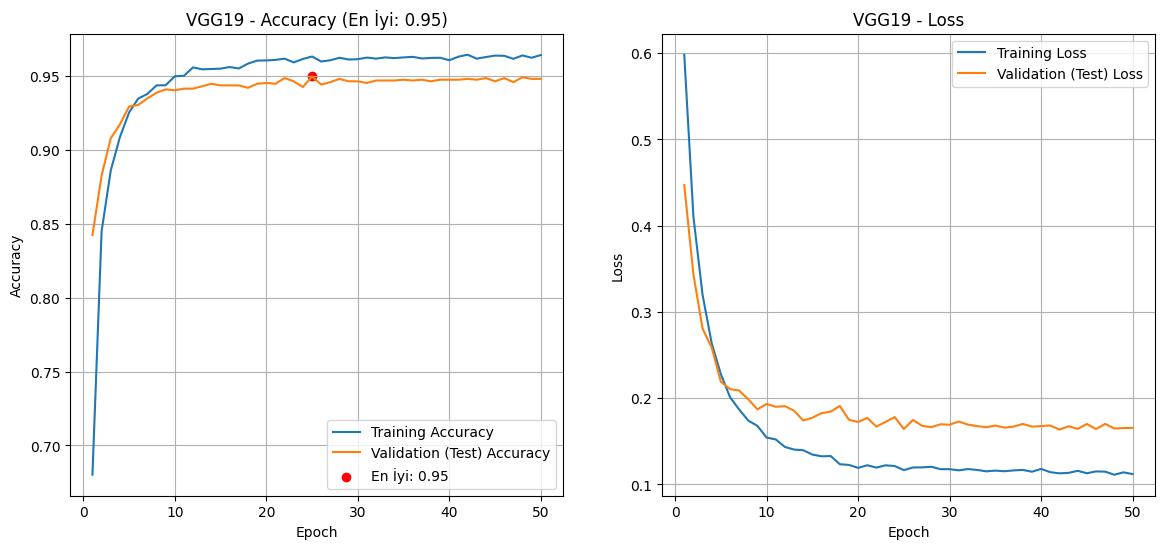

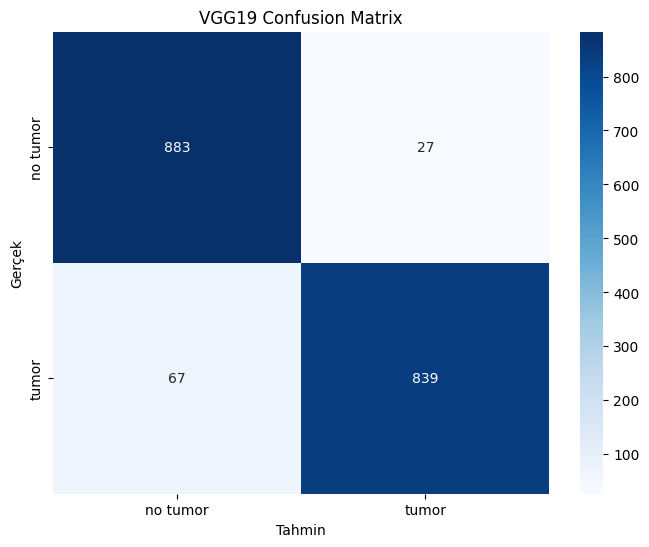

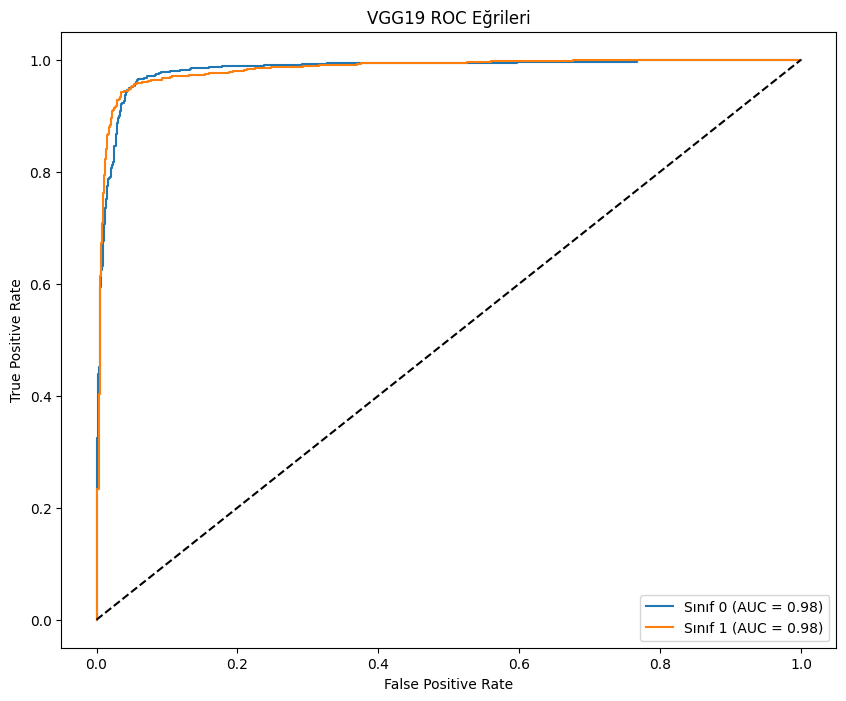

VGG19 Tamamlandı. En Yüksek Başarı: %94.99


In [ ]:
# Hazır model eğitimi
# 8.VGG19

modeli_calistir("VGG19")


 InceptionResNetV2 modeli için işlem başlatılıyor
219055592/219055592 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 466ms/step - accuracy: 0.8183 - loss: 0.4153
Epoch 1: val_accuracy improved from -inf to 0.92621, saving model to /content/drive/MyDrive/Proje_Sonuclari/InceptionResNetV2/InceptionResNetV2_best.keras
259/259 ━━━━━━━━━━━━━━━━━━━━ 182s 590ms/step - accuracy: 0.8185 - loss: 0.4148 - val_accuracy: 0.9262 - val_loss: 0.2149 - learning_rate: 1.0000e-04
Epoch 2/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 417ms/step - accuracy: 0.9338 - loss: 0.1722
Epoch 2: val_accuracy improved from 0.92621 to 0.93502, saving model to /content/drive/MyDrive/Proje_Sonuclari/InceptionResNetV2/InceptionResNetV2_best.keras
259/259 ━━━━━━━━━━━━━━━━━━━━ 119s 458ms/step - accuracy: 0.9339 - loss: 0.1722 - val_accuracy: 0.9350 - val_loss: 0.1804 - learning_rate: 1.0000e-04
Epoch 3/50
259/259 ━━━━━━━━━━━━━━━━━━━━ 0s 418ms/step - accuracy: 0.9508 - loss: 0.1388
Epoch 3: val_accuracy

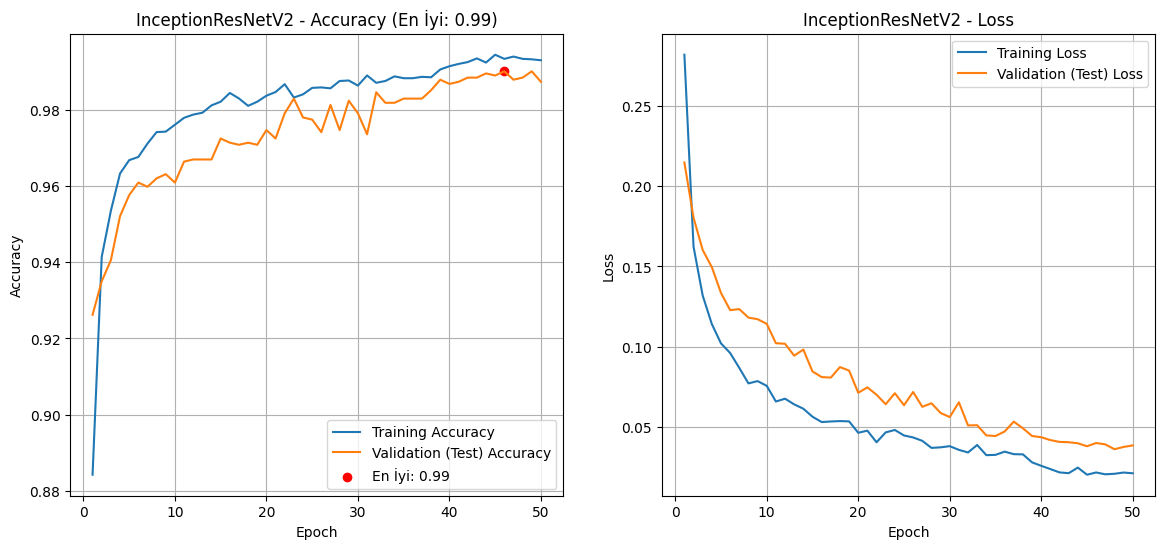

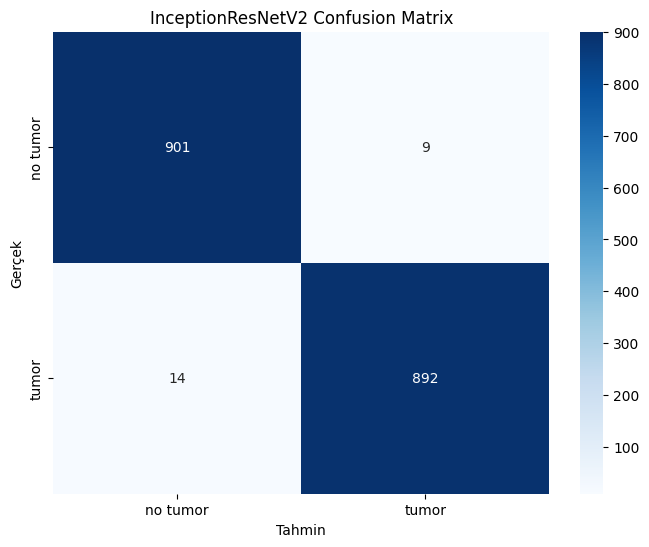

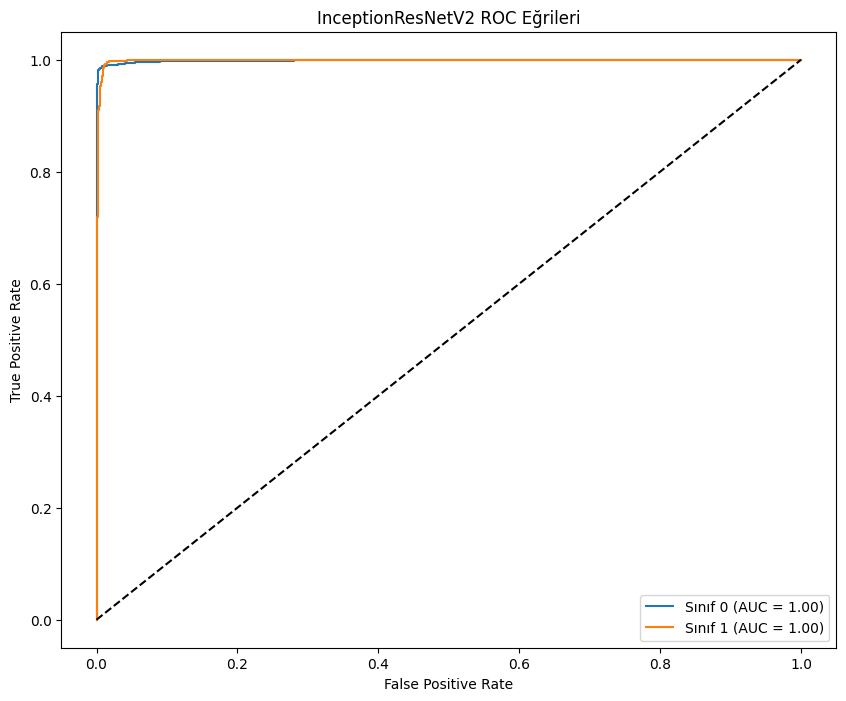

InceptionResNetV2 Tamamlandı. En Yüksek Başarı: %99.01


In [ ]:
# Hazır model eğitimi
# 9. Hibrit Model(InceptionResNetV2')

modeli_calistir("InceptionResNetV2")

/tmp/ipython-input-2015901136.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x="Model", y="Accuracy", data=df, palette="viridis")


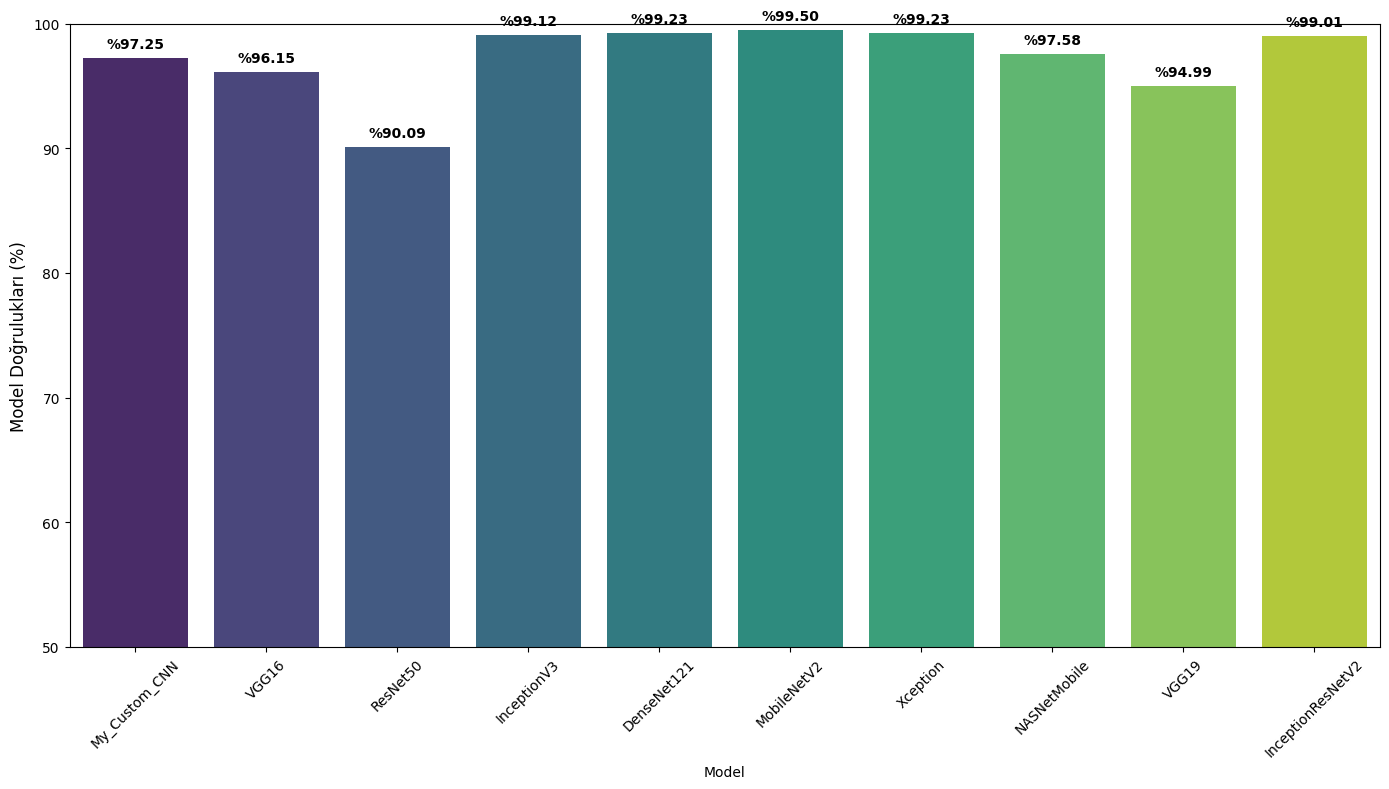

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Model isimleri ve doğruluk değerleri
modeller = ["My_Custom_CNN", "VGG16", "ResNet50", "InceptionV3", "DenseNet121",
            "MobileNetV2", "Xception", "NASNetMobile", "VGG19", "InceptionResNetV2"]

dogruluk_oranlari = [
    97.25,  # My_Custom_CNN
    96.15,  # VGG16
    90.09,  # ResNet50
    99.12,  # InceptionV3
    99.23,  # DenseNet121
    99.50,  # MOBILENETV2
    99.23,  # Xception
    97.58,  # NASNetMobile
    94.99,  # VGG19
    99.01   # InceptionResNetV2
]

# Grafik çizimi
df = pd.DataFrame({"Model": modeller, "Accuracy": dogruluk_oranlari})

plt.figure(figsize=(14,8))
ax = sns.barplot(x="Model", y="Accuracy", data=df, palette="viridis")

plt.ylabel("Model Doğrulukları (%)", fontsize=12)
plt.ylim(50, 100)
plt.xticks(rotation=45)

# Sayıları çubukların tepesine yazma
for p in ax.patches:
    ax.annotate(f'%{p.get_height():.2f}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 10), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.show()